In [1]:
import polars as pl

In [2]:
# DATASET: https://www.kaggle.com/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store
# PREPROCESS FOR TALK

# pl.scan_csv("data/2019-Nov.csv").with_columns(
#     pl.col("event_time").str.to_datetime(format="%Y-%m-%d %H:%M:%S %Z", time_zone="UTC")
# ).sink_parquet("data/2019-Nov.parquet")
# pl.scan_csv("data/2019-Oct.csv").with_columns(
#     pl.col("event_time").str.to_datetime(format="%Y-%m-%d %H:%M:%S %Z")
# ).sink_parquet("data/2019-Oct.parquet")
# pl.scan_parquet("data/*.parquet").sink_parquet("data/2019.parquet")

pl.scan_csv("data/2019-Oct.csv").with_columns(
    pl.col("event_time").str.to_datetime(format="%Y-%m-%d %H:%M:%S %Z")
).limit(10_000_000).sink_parquet("data/2019-Oct-10M.parquet")
pl.scan_csv("data/2019-Oct.csv").limit(20_000_000).sink_csv("data/2019-Oct-20M.csv")  # For Pandas run

### POLARS API

In [3]:
df = pl.read_parquet("data/2019-Oct-10M.parquet")
df.collect_schema()

Schema([('event_time', Datetime(time_unit='us', time_zone=None)),
        ('event_type', String),
        ('product_id', Int64),
        ('category_id', Int64),
        ('category_code', String),
        ('brand', String),
        ('price', Float64),
        ('user_id', Int64),
        ('user_session', String)])

In [4]:
df.head()

event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
datetime[μs],str,i64,i64,str,str,f64,i64,str
2019-10-01 00:00:00,"""view""",44600062,2103807459595387724,null,"""shiseido""",35.79,541312140,"""72d76fde-8bb3-4e00-8c23-a032df…"
2019-10-01 00:00:00,"""view""",3900821,2053013552326770905,"""appliances.environment.water_h…","""aqua""",33.2,554748717,"""9333dfbd-b87a-4708-9857-633655…"
2019-10-01 00:00:01,"""view""",17200506,2053013559792632471,"""furniture.living_room.sofa""",null,543.1,519107250,"""566511c2-e2e3-422b-b695-cf8e6e…"
2019-10-01 00:00:01,"""view""",1307067,2053013558920217191,"""computers.notebook""","""lenovo""",251.74,550050854,"""7c90fc70-0e80-4590-96f3-13c02c…"
2019-10-01 00:00:04,"""view""",1004237,2053013555631882655,"""electronics.smartphone""","""apple""",1081.98,535871217,"""c6bd7419-2748-4c56-95b4-8cec9f…"


In [5]:
df.describe()

statistic,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
str,str,str,f64,f64,str,str,f64,f64,str
"""count""","""10000000""","""10000000""",1e7,1e7,"""6775881""","""8612891""",1e7,1e7,"""9999999"""
"""null_count""","""0""","""0""",0.0,0.0,"""3224119""","""1387109""",0.0,0.0,"""1"""
"""mean""","""2019-10-04 23:35:08.081178""",null,1.0115e7,2.0567e18,null,null,296.06143,5.3176e8,null
"""std""",null,null,1.1245e7,1.6817e16,null,null,366.910058,1.7159e7,null
"""min""","""2019-10-01 00:00:00""","""cart""",1.001588e6,2.0530e18,"""accessories.bag""","""a-case""",0.0,1.83503497e8,"""00000083-8816-4d58-a9b8-f52f54…"
"""25%""","""2019-10-03 03:22:41""",null,1.005115e6,2.0530e18,null,null,65.25,5.15619279e8,null
"""50%""","""2019-10-05 01:32:45""",null,4.900087e6,2.0530e18,null,null,161.91,5.27467247e8,null
"""75%""","""2019-10-06 18:21:33""",null,1.5700074e7,2.0530e18,null,null,361.82,5.4876831e8,null
"""max""","""2019-10-08 17:26:09""","""view""",5.560003e7,2.1754e18,"""stationery.cartrige""","""zyxel""",2574.07,5.58164653e8,"""fffffa1b-a6f0-483a-8f4b-30db24…"


In [6]:
df.get_column("brand").value_counts(sort=True)
# df['brand'].value_counts(sort=True) # Same way to access column, not recommended

brand,count
str,u32
null,1387109
"""samsung""",1235686
"""apple""",1036458
"""xiaomi""",705779
"""huawei""",276702
…,…
"""sabi""",1
"""studio""",1
"""noordi""",1


In [7]:
df.select(
    pl.col("price").median().alias("median_price"),
    pl.col("brand").n_unique().alias("n_unique_brands"),
    pl.col("brand").is_not_null().sum(),
    pl.col("brand").str.len_chars().max().alias("max_brand_length"),
)

median_price,n_unique_brands,brand,max_brand_length
f64,u32,u32,u32
161.91,2673,8612891,17


In [8]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand"))

event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,median_price_over_brand
datetime[μs],str,i64,i64,str,str,f64,i64,str,f64
2019-10-01 00:00:00,"""view""",44600062,2103807459595387724,null,"""shiseido""",35.79,541312140,"""72d76fde-8bb3-4e00-8c23-a032df…",46.02
2019-10-01 00:00:00,"""view""",3900821,2053013552326770905,"""appliances.environment.water_h…","""aqua""",33.2,554748717,"""9333dfbd-b87a-4708-9857-633655…",33.2
2019-10-01 00:00:01,"""view""",17200506,2053013559792632471,"""furniture.living_room.sofa""",null,543.1,519107250,"""566511c2-e2e3-422b-b695-cf8e6e…",107.34
2019-10-01 00:00:01,"""view""",1307067,2053013558920217191,"""computers.notebook""","""lenovo""",251.74,550050854,"""7c90fc70-0e80-4590-96f3-13c02c…",411.83
2019-10-01 00:00:04,"""view""",1004237,2053013555631882655,"""electronics.smartphone""","""apple""",1081.98,535871217,"""c6bd7419-2748-4c56-95b4-8cec9f…",746.22
…,…,…,…,…,…,…,…,…,…
2019-10-08 17:26:09,"""view""",22900082,2053013561780732677,"""furniture.bedroom.pillow""","""belashoff""",25.74,518471106,"""708497d0-bed7-476b-af47-66ebda…",25.74
2019-10-08 17:26:09,"""view""",32100001,2060237588744111062,null,null,164.1,514437524,"""f8fc5c52-ae97-4a64-b6f4-fa3f5f…",107.34
2019-10-08 17:26:09,"""view""",26400265,2053013563651392361,null,"""lucente""",154.19,547749418,"""e22d0270-8dea-4cc1-ae99-e78a58…",215.71


In [9]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand")).group_by(
    "event_type", "product_id", "category_id", "category_code", "brand", "price", "median_price_over_brand"
).agg("user_id")

event_type,product_id,category_id,category_code,brand,price,median_price_over_brand,user_id
str,i64,i64,str,str,f64,f64,list[i64]
"""view""",5800804,2053013553945772349,"""electronics.audio.subwoofer""",null,74.65,107.34,"[552729249, 517456238, … 512854745]"
"""view""",17700651,2053013558861496931,null,null,35.26,107.34,"[515437110, 515437110, 518049639]"
"""view""",5700260,2053013553970938175,"""auto.accessories.player""","""winca""",296.02,373.24,"[513479384, 513479384, … 518494861]"
"""view""",26022616,2053013562837697343,null,null,7.81,107.34,"[549463632, 556466569, … 542222291]"
"""view""",1002524,2053013555631882655,"""electronics.smartphone""","""apple""",513.45,746.22,"[515501936, 517985957, … 550482655]"
…,…,…,…,…,…,…,…
"""view""",12703880,2053013553559896355,null,"""nexen""",90.09,63.19,"[546520540, 542149521, … 542149521]"
"""view""",5500266,2053013563139687243,null,"""panasonic""",210.82,74.34,"[535946291, 517583987, … 517583987]"
"""view""",17300082,2053013553853497655,null,"""dunhill""",39.23,60.23,"[513938330, 513587255, … 517849666]"


## Eager vs Lazy Performance

In [10]:
## NOTE: Restart kernel and clean cells at this point to free memory
import polars as pl

In [11]:
df = pl.read_parquet("data/2019-Oct-10M.parquet")  # Eager read

In [12]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand")).write_parquet(
    "data/2019-Oct-10M_eager.parquet"
)

In [13]:
del df

In [14]:
df_lazy_brand = pl.scan_parquet("data/2019-Oct-10M.parquet").select("brand").unique() # TODO

In [15]:
df_lazy = (
    pl.scan_parquet("data/2019-Oct.parquet")
    .join(df_lazy_brand, on="brand", how="inner")
    .with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand"))
    .group_by("event_type", "product_id", "category_id", "category_code", "brand", "price", "median_price_over_brand")
    .agg(pl.col("user_id"))
    .filter(pl.col("product_id") > 100000)
)

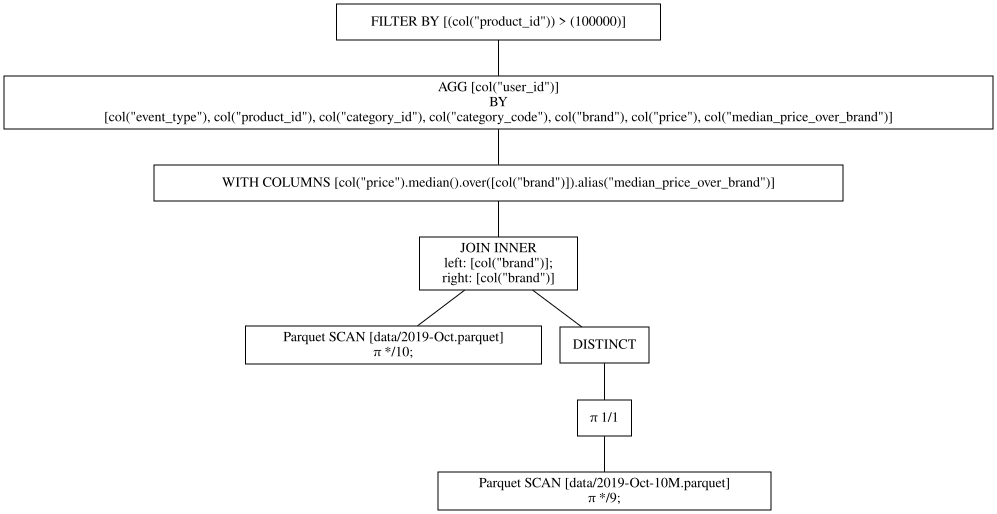

In [16]:
df_lazy.show_graph(optimized=False)

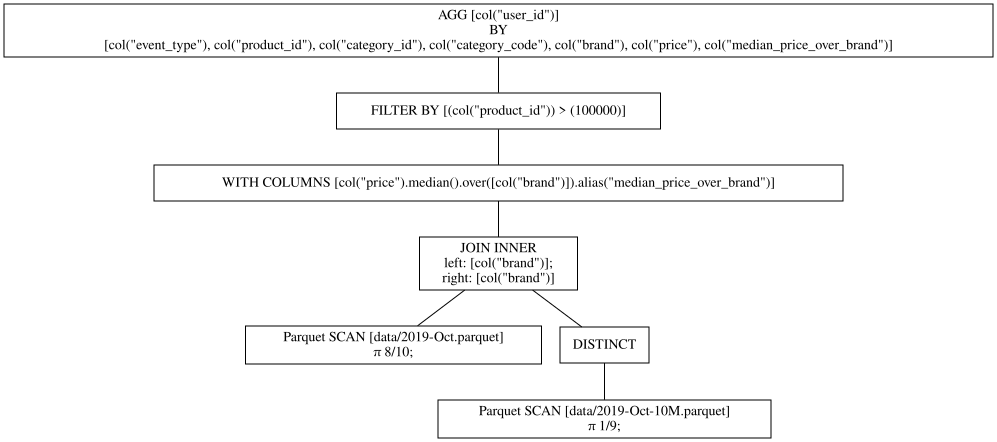

In [17]:
df_lazy.show_graph(optimized=True)

In [18]:
df_lazy.collect(engine="streaming", no_optimization=True).write_parquet("data/2019-Oct-10M_lazy_no_opt.parquet")

/tmp/ipykernel_26737/2153965439.py:1: DeprecationWarning: optimization flag `no_optimization` is deprecated. Please use `optimizations` parameter
(Deprecated in version 1.30.0)
  df_lazy.collect(engine="streaming", no_optimization=True).write_parquet("data/2019-Oct-10M_lazy_no_opt.parquet")


In [ ]:
df_lazy.collect(engine="streaming").write_parquet("data/2019-Oct-10M_lazy_opt.parquet")

## Arrow interoperability

In [ ]:
df = pl.read_parquet("data/2019-Oct-10M.parquet")

In [ ]:
df.estimated_size("mb")

In [ ]:
df_pd = df.to_pandas(use_pyarrow_extension_array=False)
df_pd.head()

In [ ]:
df_pd_arrow = df.to_pandas(use_pyarrow_extension_array=True)
df_pd_arrow.head()

In [ ]:
import duckdb

conn = duckdb.connect("test.duckdb")

In [ ]:
conn.sql("CREATE OR REPLACE TABLE pandas_backend as SELECT * from df_pd")

In [ ]:
conn.sql("CREATE OR REPLACE  TABLE pandas_arrow as SELECT * from df_pd_arrow")

In [ ]:
conn.sql("CREATE OR REPLACE TABLE polars as SELECT * from df")

In [ ]:
conn.close()

# GPU ENGINE

In [ ]:
## https://developer.nvidia.com/blog/polars-gpu-engine-powered-by-rapids-cudf-now-available-in-open-beta
## Colab notebook:
## https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/accelerated_data_processing_examples/polars_gpu_engine_demo.ipynb?utm_source=nvidia+mktg&utm_medium=web&utm_campaign=polars+launch